In [33]:
!git clone https://github.com/ultralytics/yolov5
%cd yolov5

fatal: destination path 'yolov5' already exists and is not an empty directory.
/content/yolov5/yolov5


In [34]:
%pwd

'/content/yolov5/yolov5'

In [35]:
!pip install -qr requirements.txt

In [36]:
import torch
from IPython.display import Image,clear_output
print(torch.__version__,torch.cuda.get_device_name())

2.11.0+cu130 Tesla T4


In [37]:
import zipfile
import os

zip_path = "/content/data.zip"
extract_path = "/content/data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP file extracted successfully!")
print("Files:", os.listdir(extract_path))

ZIP file extracted successfully!
Files: ['.ipynb_checkpoints', 'data.yaml', 'test', 'train', 'valid']


In [38]:
%cd /content/data
%pwd


/content/data


'/content/data'

In [39]:
%cat data.yaml

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 5
names: ["bad", "good", "guzel", "i loveyou", "thank you"]


In [40]:
import yaml
with open("data.yaml",'r') as stream:
  num_classes = str(yaml.safe_load(stream)['nc'])
num_classes

'5'

In [41]:
%cat /content/yolov5/models/yolov5s.yaml

# Ultralytics 🚀 AGPL-3.0 License - https://ultralytics.com/license

# Ultralytics YOLOv5s object detection model with P3/8 - P5/32 outputs
# Model docs: https://docs.ultralytics.com/models/yolov5
# Task docs: https://docs.ultralytics.com/tasks/detect
# Example usage: python train.py --cfg yolov5s.yaml --data coco.yaml

# Parameters
nc: 80 # number of classes
depth_multiple: 0.33 # model depth multiple
width_multiple: 0.50 # layer channel multiple
anchors:
  - [10, 13, 16, 30, 33, 23] # P3/8 small-object anchors
  - [30, 61, 62, 45, 59, 119] # P4/16 medium-object anchors
  - [116, 90, 156, 198, 373, 326] # P5/32 large-object anchors

# YOLOv5 v6.0 backbone
backbone:
  # [from, number, module, args]
  [
    [-1, 1, Conv, [64, 6, 2, 2]], # 0-P1/2
    [-1, 1, Conv, [128, 3, 2]], # 1-P2/4
    [-1, 3, C3, [128]],
    [-1, 1, Conv, [256, 3, 2]], # 3-P3/8
    [-1, 6, C3, [256]],
    [-1, 1, Conv, [512, 3, 2]], # 5-P4/16
    [-1, 9, C3, [512]],
    [-1, 1, Conv, [1024, 3, 2]], # 7-P5/32
    [-1

In [42]:
from IPython.core.magic import register_line_cell_magic

@register_line_cell_magic
def writetemplate(line,cell):
  with open(line,'w') as f:
    f.write(cell.format(**globals()))

In [43]:
%%writetemplate /content/yolov5/models/custom_yolov5s.yaml
# Ultralytics 🚀 AGPL-3.0 License - https://ultralytics.com/license

# Ultralytics YOLOv5s object detection model with P3/8 - P5/32 outputs
# Model docs: https://docs.ultralytics.com/models/yolov5
# Task docs: https://docs.ultralytics.com/tasks/detect
# Example usage: python train.py --cfg yolov5s.yaml --data coco.yaml

# Parameters
nc: {num_classes} # number of classes
depth_multiple: 0.33 # model depth multiple
width_multiple: 0.50 # layer channel multiple
anchors:
  - [10, 13, 16, 30, 33, 23] # P3/8 small-object anchors
  - [30, 61, 62, 45, 59, 119] # P4/16 medium-object anchors
  - [116, 90, 156, 198, 373, 326] # P5/32 large-object anchors

# YOLOv5 v6.0 backbone
backbone:
  # [from, number, module, args]
  [
    [-1, 1, Conv, [64, 6, 2, 2]], # 0-P1/2
    [-1, 1, Conv, [128, 3, 2]], # 1-P2/4
    [-1, 3, C3, [128]],
    [-1, 1, Conv, [256, 3, 2]], # 3-P3/8
    [-1, 6, C3, [256]],
    [-1, 1, Conv, [512, 3, 2]], # 5-P4/16
    [-1, 9, C3, [512]],
    [-1, 1, Conv, [1024, 3, 2]], # 7-P5/32
    [-1, 3, C3, [1024]],
    [-1, 1, SPPF, [1024, 5]], # 9
  ]

# YOLOv5 v6.0 head
head: [
    [-1, 1, Conv, [512, 1, 1]],
    [-1, 1, nn.Upsample, [None, 2, "nearest"]],
    [[-1, 6], 1, Concat, [1]], # cat backbone P4
    [-1, 3, C3, [512, False]], # 13

    [-1, 1, Conv, [256, 1, 1]],
    [-1, 1, nn.Upsample, [None, 2, "nearest"]],
    [[-1, 4], 1, Concat, [1]], # cat backbone P3
    [-1, 3, C3, [256, False]], # 17 (P3/8-small)

    [-1, 1, Conv, [256, 3, 2]],
    [[-1, 14], 1, Concat, [1]], # cat head P4
    [-1, 3, C3, [512, False]], # 20 (P4/16-medium)

    [-1, 1, Conv, [512, 3, 2]],
    [[-1, 10], 1, Concat, [1]], # cat head P5
    [-1, 3, C3, [1024, False]], # 23 (P5/32-large)

    [[17, 20, 23], 1, Detect, [nc, anchors]], # Detect(P3, P4, P5)
  ]


In [44]:
import yaml
p = '/content/data/data.yaml'
d = yaml.safe_load(open(p))
d['train'] = '/content/data/train/images'
d['test']  = '/content/data/test/images'
yaml.safe_dump(d, open(p, 'w'))

In [47]:
# Example: Train YOLOv5s on the COCO128 dataset for 3 epochs
%%time
%cd /content/yolov5/
%env WANDB_MODE=disabled
!python train.py --img 448 --batch 16 --epochs 150 \
  --data /content/data/data.yaml \
  --cfg ./models/custom_yolov5s.yaml \
  --weights yolov5s.pt --name yolov5s_results --cache ram

/content/yolov5
env: WANDB_MODE=disabled
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791712288.129417   21845 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=./models/custom_yolov5s.yaml, data=/content/data/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=150, batch_size=16, imgsz=448, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=yolov5s_results, exist_ok=False, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
github: u

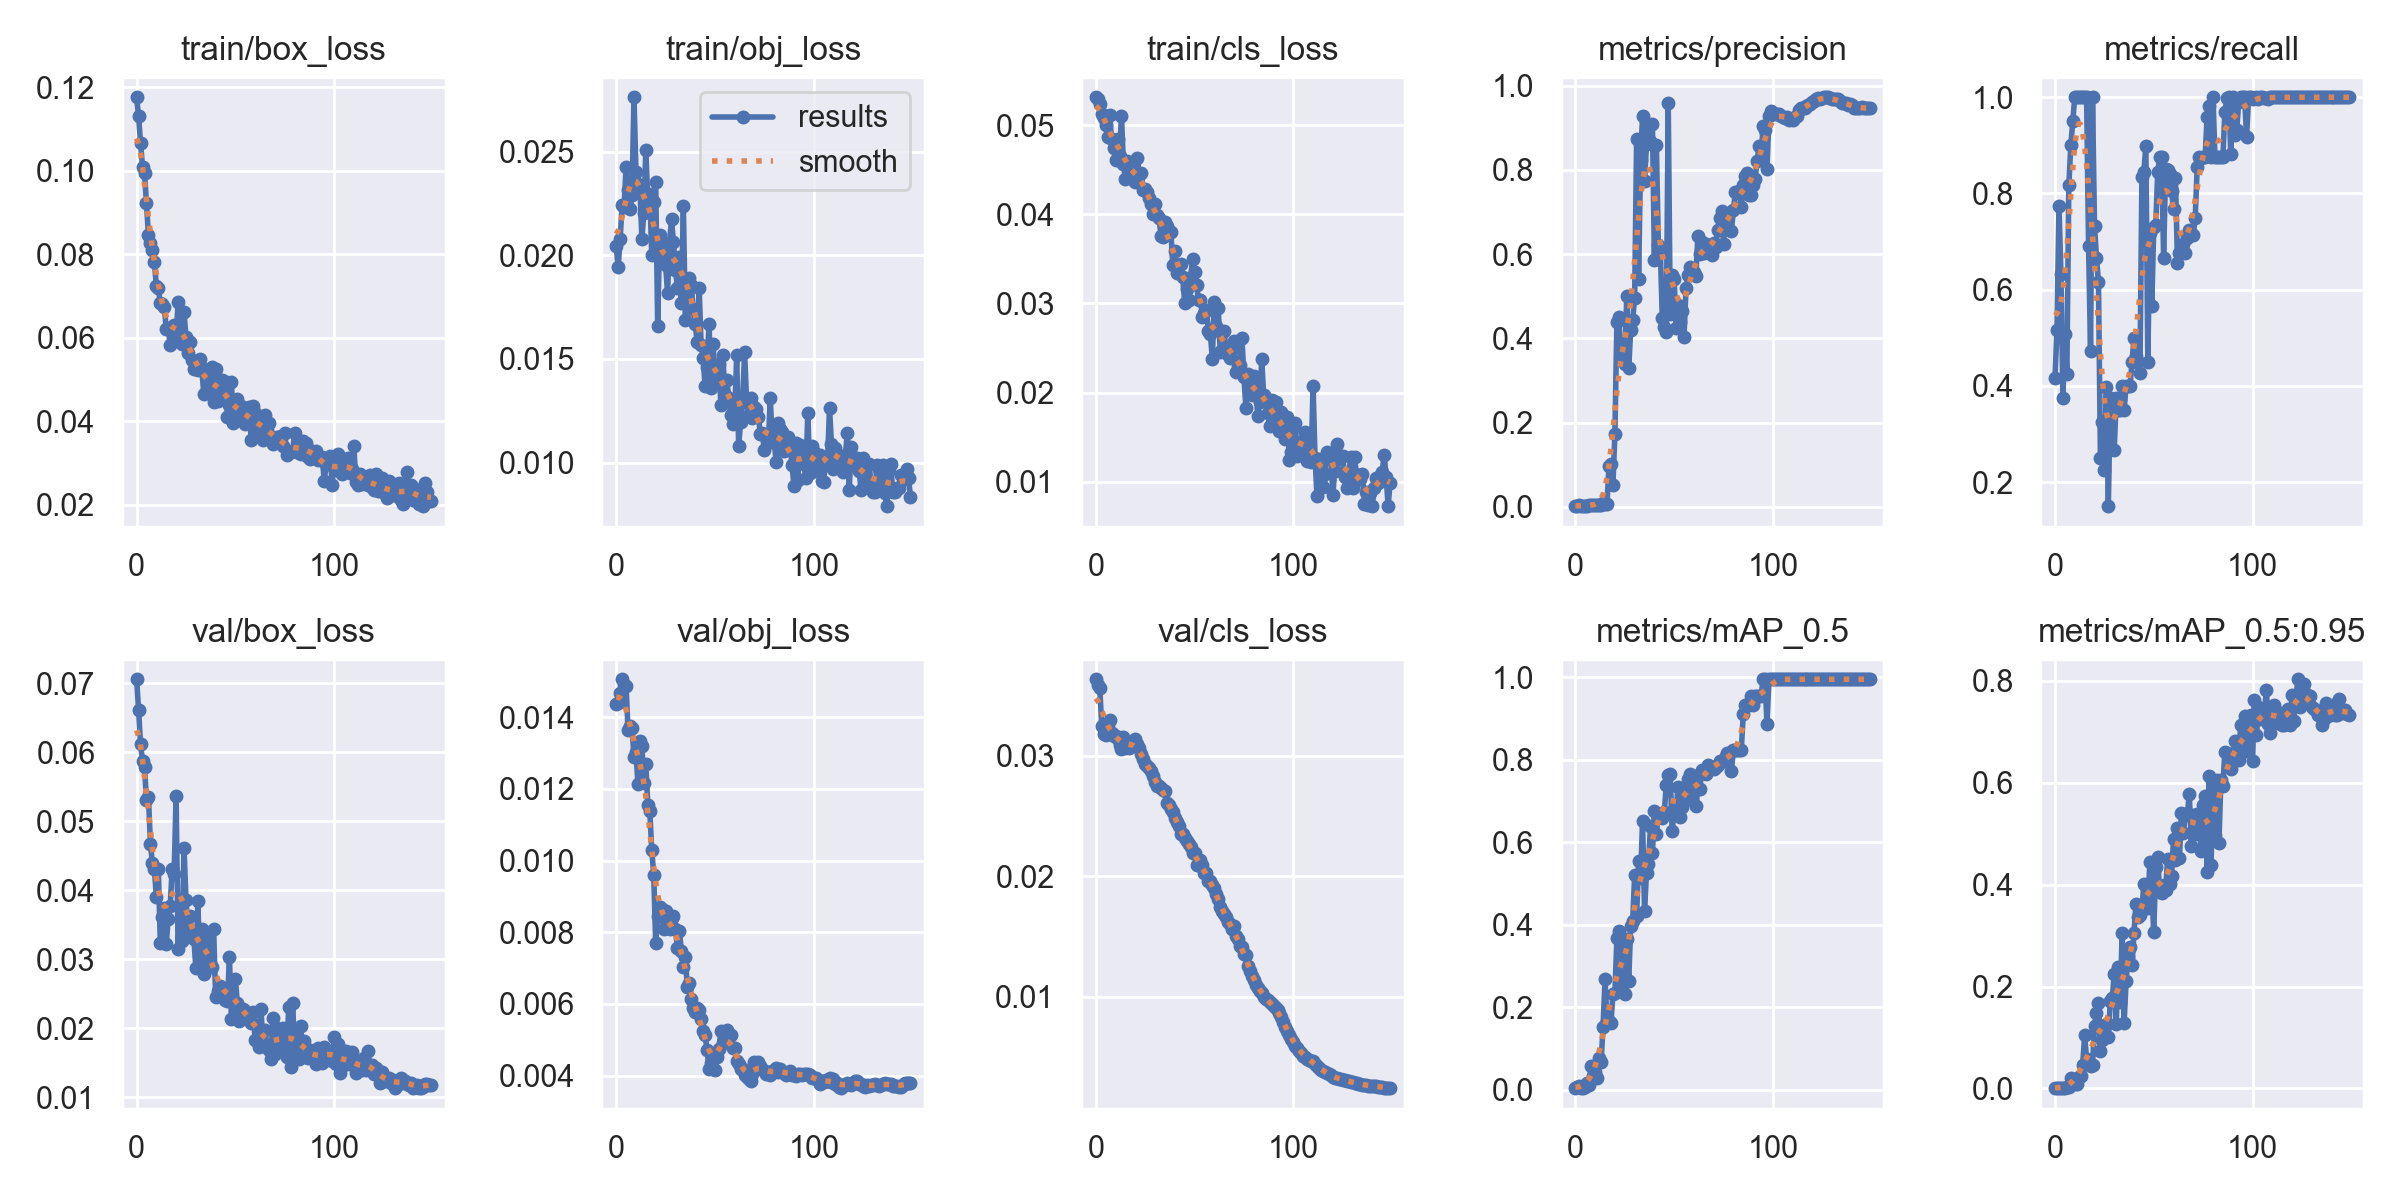

In [48]:
from utils.plots import plot_results
Image(filename='/content/yolov5/runs/train/yolov5s_results5/results.png',width=1000)

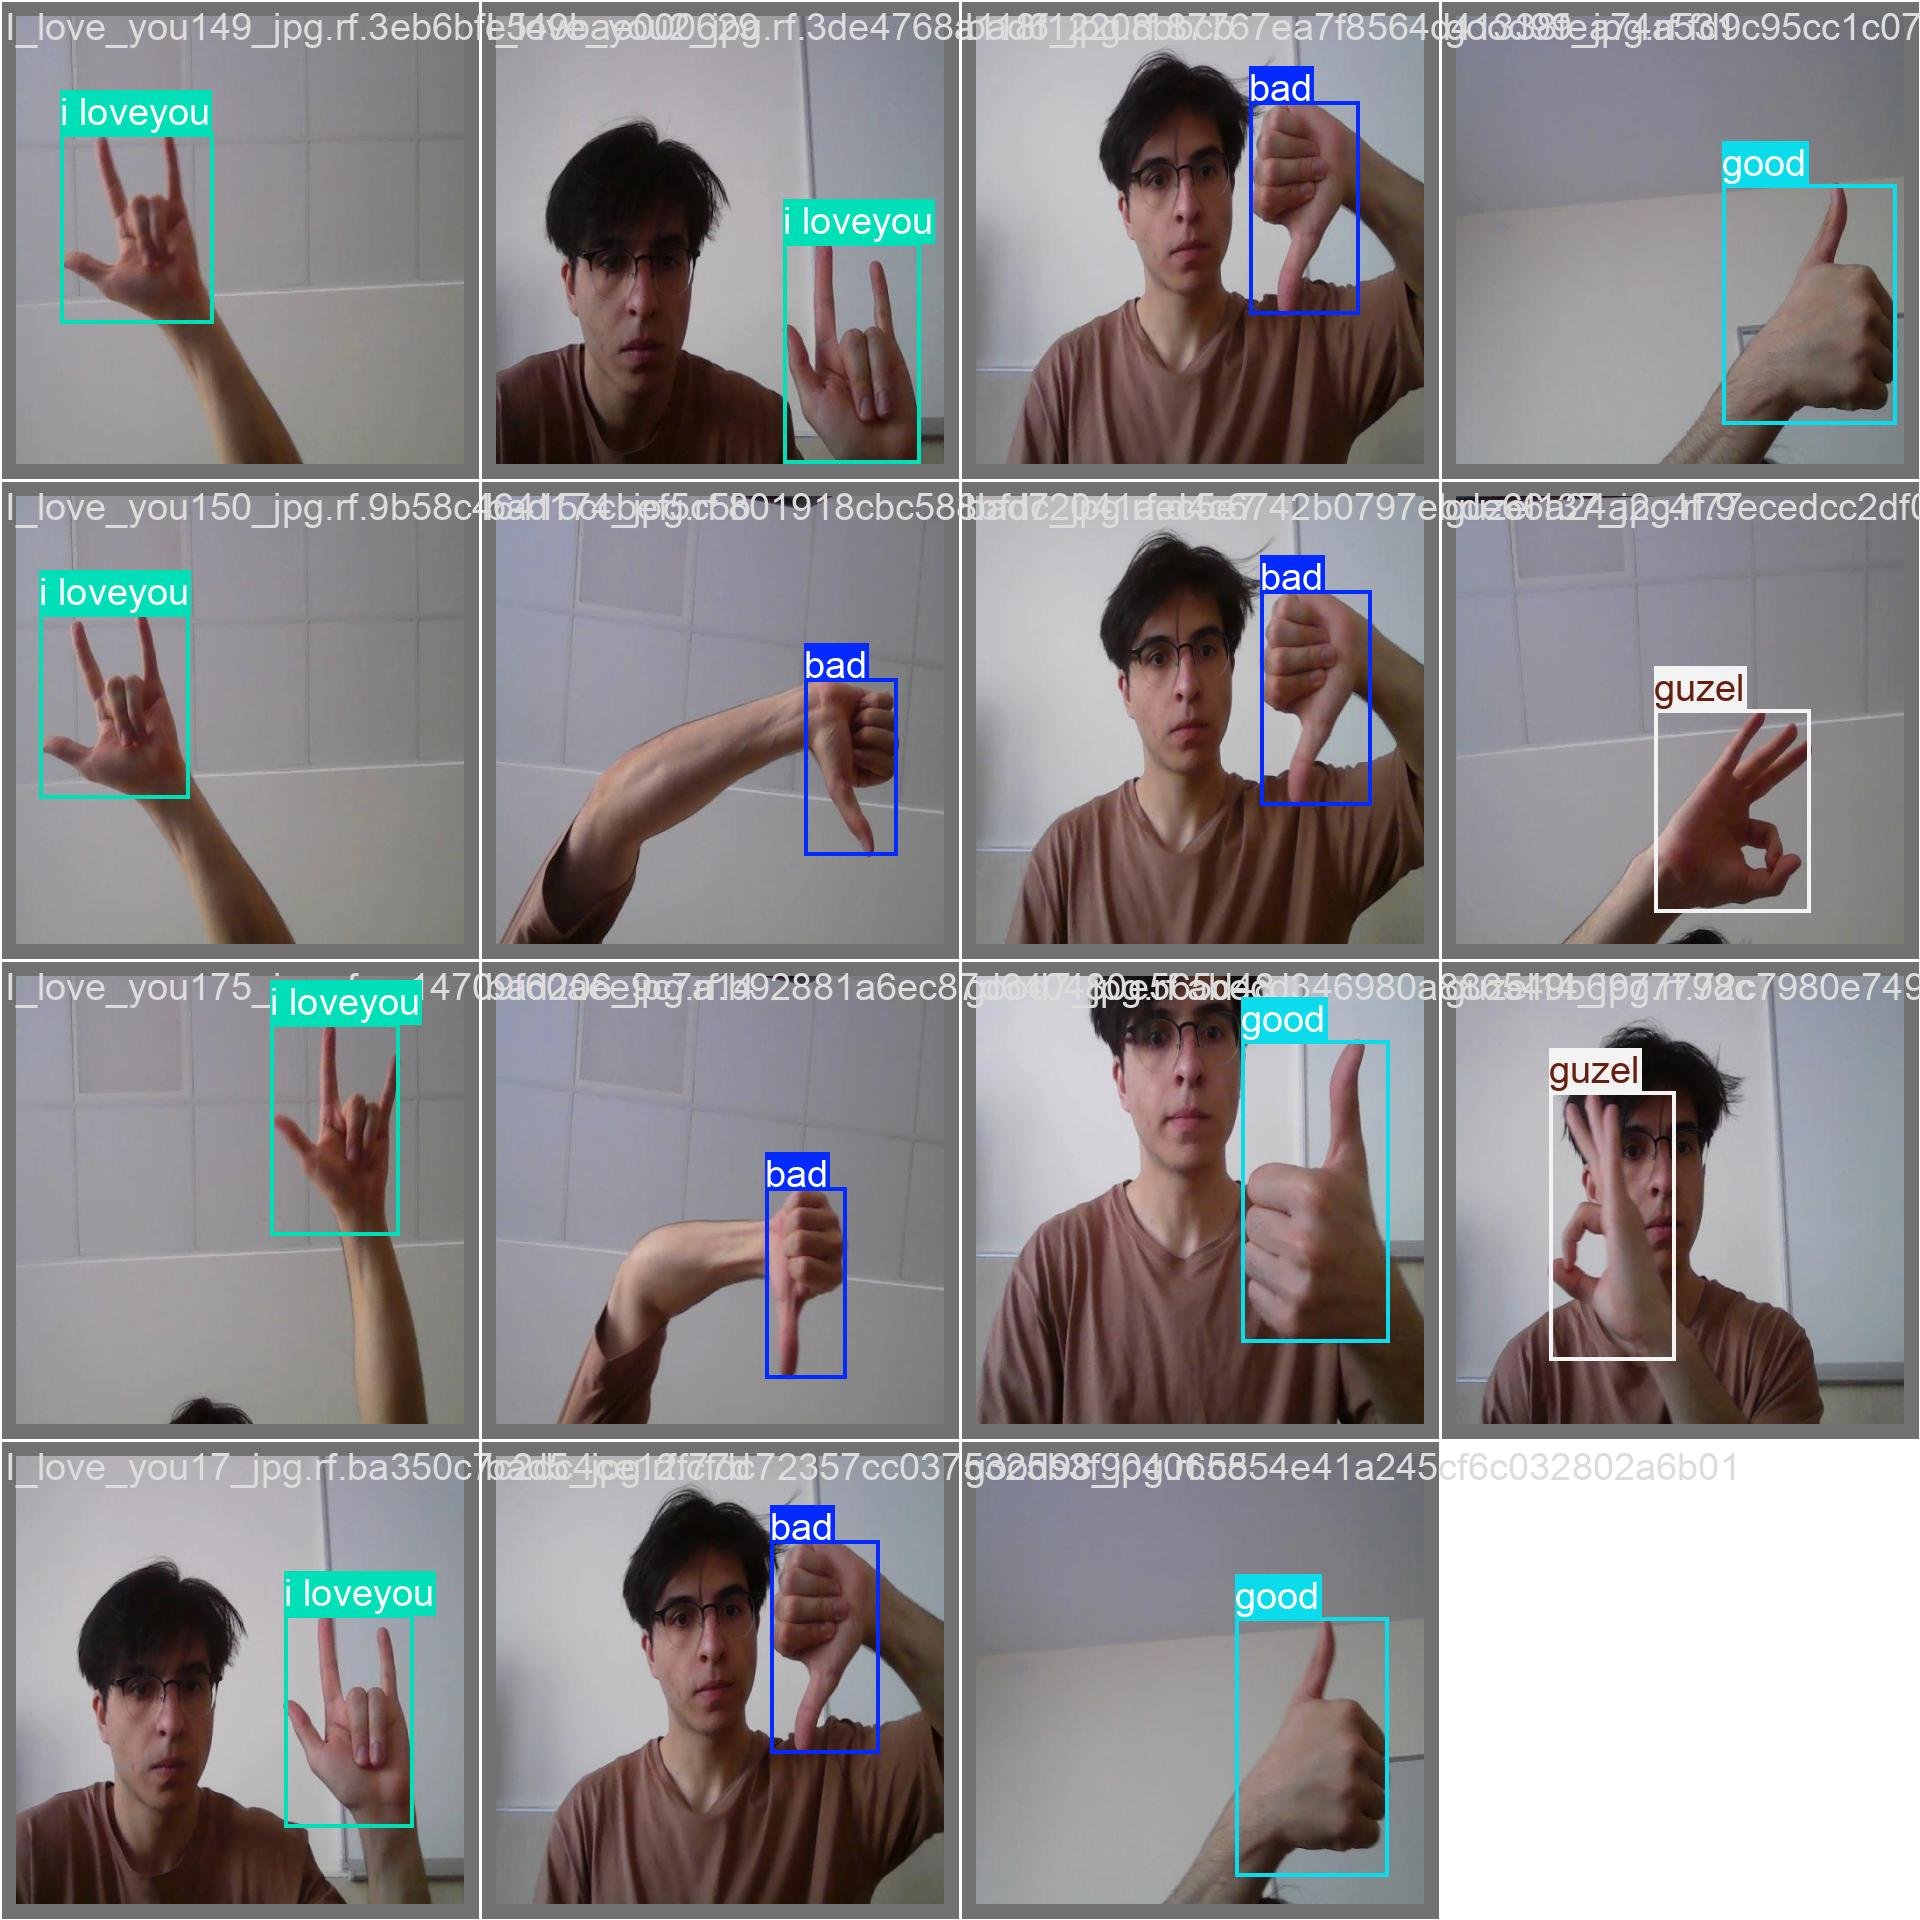

In [55]:
Image(filename='/content/yolov5/runs/train/yolov5s_results5/val_batch0_labels.jpg',width=1000)

In [56]:
%cd /content/yolov5/

/content/yolov5


In [57]:
!python detect.py --weights 'runs/train/yolov5s_results5/weights/best.pt' --img 448  --conf 0.5 --source /content/data/test/images

detect: weights=['runs/train/yolov5s_results5/weights/best.pt'], source=/content/data/test/images, data=data/coco128.yaml, imgsz=[448, 448], conf_thres=0.5, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
custom_YOLOv5s summary: 68 layers, 7,023,610 parameters, 0 gradients, 15.8 GFLOPs
image 1/8 /content/data/test/images/I_love_you185_jpg.rf.e566aa1761acf906c359c890b6e2b47b.jpg: 448x448 1 i loveyou, 9.9ms
image 2/8 /content/data/test/images/I_love_you47_jpg.rf.da334dc6b2722645de5b89b17f50625a.jpg: 448x448 1 i loveyou, 10.5ms
image 3/8 /content/data/test/images/bad102_jpg.rf.91119d51